# Amazon Product Data Analysis

This notebook analyzes the cleaned Amazon product dataset. It describes products, prices, discounts, ratings, and rating counts. The dataset does not include order dates, customer purchases, or units sold, so it cannot show sales over time or actual sales volume.


## Step 1: Import the tools

Pandas works with tables, NumPy helps with calculations, `statistics` provides simple averages, and Matplotlib creates charts.


In [1]:
import pandas as pd
import numpy as np
import statistics
import matplotlib.pyplot as plt


## Step 2: Load the cleaned data


In [2]:
df = pd.read_csv("../Processed_Datasets/amazon_cleaned.csv")
df.head()


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,main_category
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,Computers&Accessories
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43,4.0,43994.0,"Compatible with all Type C enabled devices, be...",Computers&Accessories
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,Computers&Accessories
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,Computers&Accessories
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,Computers&Accessories


## Step 3: Check the dataset

Check the number of rows and columns, column types, and missing values.


In [3]:
print("Rows and columns:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())


Rows and columns: (1348, 10)

Column types:
product_id                 str
product_name               str
category                   str
discounted_price       float64
actual_price           float64
discount_percentage      int64
rating                 float64
rating_count           float64
about_product              str
main_category              str
dtype: object

Missing values:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
main_category          0
dtype: int64


## Step 4: Calculate basic summaries

These summaries describe the product listings. They are not sales totals.


In [4]:
print("Average discounted price:", round(statistics.mean(df["discounted_price"]), 2))
print("Median discounted price:", round(statistics.median(df["discounted_price"]), 2))
print("Average discount percentage:", round(statistics.mean(df["discount_percentage"]), 2))
print("Average rating:", round(np.mean(df["rating"]), 2))
print("Average rating count:", round(statistics.mean(df["rating_count"]), 2))


Average discounted price: 3310.27
Median discounted price: 899.0
Average discount percentage: 46.66
Average rating: 4.09
Average rating count: 17656.85


## Step 5: Compare broad product categories

Show how many product listings are in each broad category, along with average price, discount, and rating.


In [5]:
category_summary = df.groupby("main_category").agg(
    product_count=("product_id", "count"),
    average_discounted_price=("discounted_price", "mean"),
    average_discount=("discount_percentage", "mean"),
    average_rating=("rating", "mean")
).sort_values("product_count", ascending=False)

category_summary.round(2)


,product_count,average_discounted_price,average_discount,average_rating
main_category,,,,
Electronics,490,6225.87,49.91,4.08
Home&Kitchen,447,2331.13,40.17,4.04
Computers&Accessories,373,951.37,53.09,4.15
OfficeProducts,31,301.58,12.35,4.31
HomeImprovement,2,337.00,57.50,4.25
MusicalInstruments,2,638.00,46.00,3.90
Car&Motorbike,1,2339.00,42.00,3.80
Health&PersonalCare,1,899.00,53.00,4.00
Toys&Games,1,150.00,0.00,4.30


## Step 6: Create charts


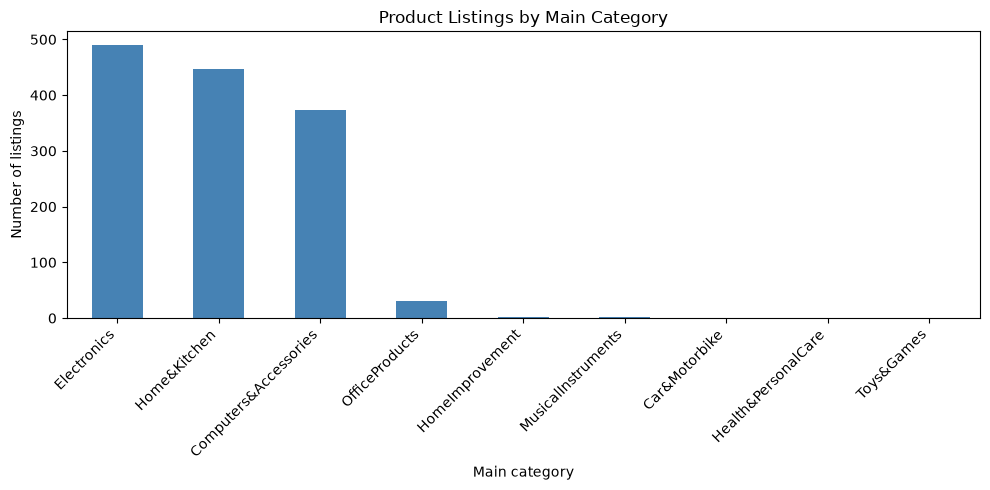

In [6]:
category_summary["product_count"].plot(kind="bar", figsize=(10, 5), color="steelblue")
plt.title("Product Listings by Main Category")
plt.xlabel("Main category")
plt.ylabel("Number of listings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


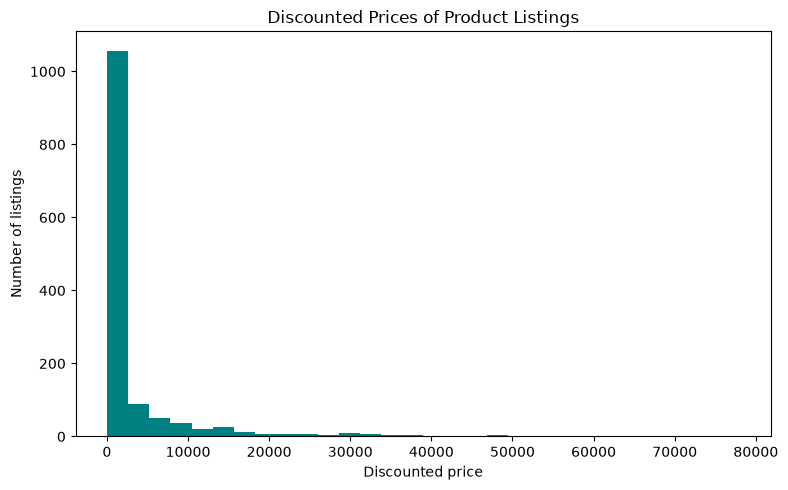

In [7]:
df["discounted_price"].plot(kind="hist", bins=30, figsize=(8, 5), color="teal")
plt.title("Discounted Prices of Product Listings")
plt.xlabel("Discounted price")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()


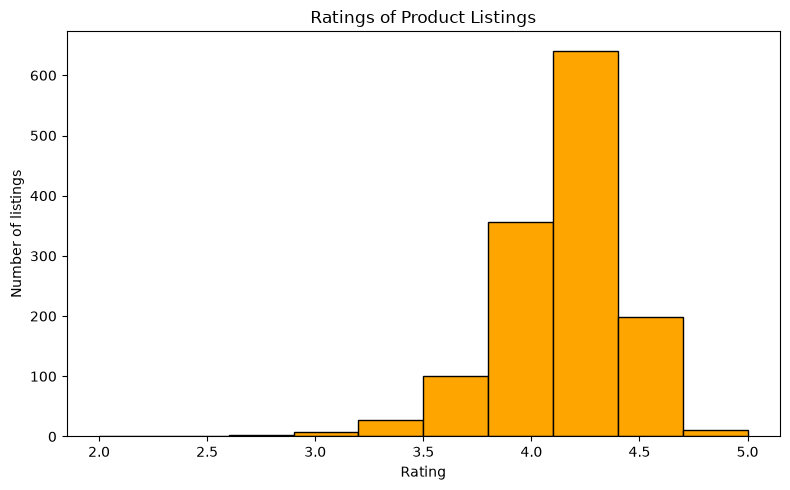

In [8]:
df["rating"].plot(kind="hist", bins=10, figsize=(8, 5), color="orange", edgecolor="black")
plt.title("Ratings of Product Listings")
plt.xlabel("Rating")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()


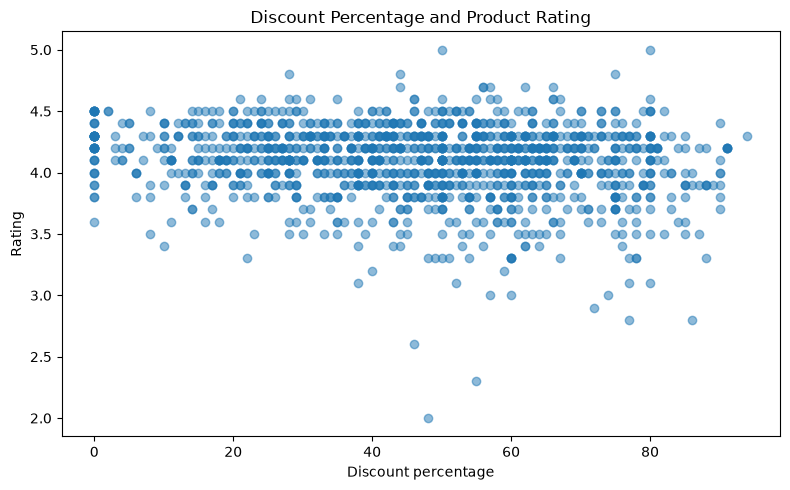

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df["discount_percentage"], df["rating"], alpha=0.5)
plt.title("Discount Percentage and Product Rating")
plt.xlabel("Discount percentage")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()


## Step 7: Five observations from the dataset

These are descriptive observations about the product listings, not conclusions about actual sales.


In [10]:
largest_category = category_summary.index[0]
lowest_price_category = category_summary["average_discounted_price"].idxmin()
highest_rating_category = category_summary["average_rating"].idxmax()

print("1. The dataset contains", len(df), "product listings across", df["main_category"].nunique(), "main categories.")
print("2. The category with the most listings is", largest_category, "with", int(category_summary.loc[largest_category, "product_count"]), "listings.")
print("3. The median discounted price is", round(statistics.median(df["discounted_price"]), 2), ".")
print("4. The average product rating is", round(np.mean(df["rating"]), 2), "out of 5.")
print("5. The category with the lowest average discounted price is", lowest_price_category, "at", round(category_summary.loc[lowest_price_category, "average_discounted_price"], 2), ".")
print("\nReminder: The dataset has no order dates, purchases, or units sold, so these observations do not measure sales trends or sales volume.")


1. The dataset contains 1348 product listings across 9 main categories.
2. The category with the most listings is Electronics with 490 listings.
3. The median discounted price is 899.0 .
4. The average product rating is 4.09 out of 5.
5. The category with the lowest average discounted price is Toys&Games at 150.0 .

Reminder: The dataset has no order dates, purchases, or units sold, so these observations do not measure sales trends or sales volume.
